In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt


df = pd.read_csv(r'C:\Users\USER\OneDrive\Documents\FoodPrices\data\food-prices-kenya.csv')

df.shape

(2742, 9)

In [3]:
def data(sample):
    df.head()
    df.dtypes
    df.info()
    df.describe().T
    df.value_counts()
    df.isna().sum()

sample = df
print(data(sample))

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB
None


In [4]:
df.dtypes

date              str
region            str
county            str
market            str
commodity         str
price_type        str
unit              str
price_kes     float64
price_usd     float64
dtype: object

In [5]:
df['date'].unique()

<StringArray>
['2015-01-15', '2015-02-15', '2015-03-15', '2015-04-15', '2015-05-15',
 '2015-06-15', '2015-07-15', '2015-08-15', '2015-09-15', '2015-10-15',
 ...
 '2014-04-15', '2014-05-15', '2014-06-15', '2014-07-15', '2014-08-15',
 '2014-09-15', '2014-10-15', '2014-11-15', '2014-12-15', '2016-04-15']
Length: 168, dtype: str

In [6]:
#turn the date column into real dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")
# df["date"].sample(20, random_state=42)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        2742 non-null   datetime64[us]
 1   region      2683 non-null   str           
 2   county      2683 non-null   str           
 3   market      2742 non-null   str           
 4   commodity   2742 non-null   str           
 5   price_type  2742 non-null   str           
 6   unit        2742 non-null   str           
 7   price_kes   2742 non-null   float64       
 8   price_usd   2742 non-null   float64       
dtypes: datetime64[us](1), float64(2), str(6)
memory usage: 192.9 KB


In [8]:
# extracting year from the date
df['year'] = df['date'].dt.year

#  extracting the month from the date
df['month'] = df['date'].dt.month

In [9]:
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
2372,2007-09-15,Coast,Mombasa,Mombasa,Maize,Wholesale,90 KG,1230.0,18.35,2007,9
2159,2017-08-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,4456.0,43.01,2017,8
2422,2011-11-15,Coast,Mombasa,Mombasa,Maize,Wholesale,90 KG,3284.0,34.97,2011,11
698,2015-10-15,Eastern,Kitui,Kitui,Maize,Retail,KG,34.0,0.33,2015,10
785,2009-01-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,49.0,0.61,2009,1


In [10]:
# checking duplicates
df.duplicated().sum()

np.int64(0)

In [11]:
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

market
Hola    59
dtype: int64


In [12]:
# replacing the missing value in county to Tana River 
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')

In [13]:
df.loc[df['market'] == 'Hola', 'county']

404    Tana River
405    Tana River
406    Tana River
407    Tana River
408    Tana River
409    Tana River
410    Tana River
411    Tana River
412    Tana River
413    Tana River
414    Tana River
415    Tana River
416    Tana River
417    Tana River
418    Tana River
419    Tana River
420    Tana River
421    Tana River
422    Tana River
423    Tana River
424    Tana River
425    Tana River
426    Tana River
427    Tana River
428    Tana River
429    Tana River
430    Tana River
431    Tana River
432    Tana River
433    Tana River
434    Tana River
435    Tana River
436    Tana River
437    Tana River
438    Tana River
439    Tana River
440    Tana River
441    Tana River
442    Tana River
443    Tana River
444    Tana River
445    Tana River
446    Tana River
447    Tana River
448    Tana River
449    Tana River
450    Tana River
451    Tana River
452    Tana River
453    Tana River
454    Tana River
455    Tana River
456    Tana River
457    Tana River
458    Tana River
459    Tan

In [14]:
# replacing missing value in region to Coast
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [15]:
df.loc[df['market'] == 'Hola', 'region']

404    Coast
405    Coast
406    Coast
407    Coast
408    Coast
409    Coast
410    Coast
411    Coast
412    Coast
413    Coast
414    Coast
415    Coast
416    Coast
417    Coast
418    Coast
419    Coast
420    Coast
421    Coast
422    Coast
423    Coast
424    Coast
425    Coast
426    Coast
427    Coast
428    Coast
429    Coast
430    Coast
431    Coast
432    Coast
433    Coast
434    Coast
435    Coast
436    Coast
437    Coast
438    Coast
439    Coast
440    Coast
441    Coast
442    Coast
443    Coast
444    Coast
445    Coast
446    Coast
447    Coast
448    Coast
449    Coast
450    Coast
451    Coast
452    Coast
453    Coast
454    Coast
455    Coast
456    Coast
457    Coast
458    Coast
459    Coast
460    Coast
461    Coast
462    Coast
Name: region, dtype: str

In [16]:
#sorting the date from the earliest to the latest date
highest_date = df["date"].max()
print(highest_date)
lowest_date = df["date"].min()
print(lowest_date)

2019-12-15 00:00:00
2006-01-15 00:00:00


In [17]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,2742,2013-12-07 12:42:32.297593,2006-01-15 00:00:00,2010-05-15 00:00:00,2014-11-15 00:00:00,2017-06-15 00:00:00,2019-12-15 00:00:00,NaN
price_kes,2742.0,2239.335748,6.0,55.0,1313.335,3733.0,10350.0,2576.989414
price_usd,2742.0,25.127372,0.074,0.6,18.17,45.0825,115.15,28.185014
year,2742.0,2013.438366,2006.0,2010.0,2014.0,2017.0,2019.0,4.081936
month,2742.0,6.504012,1.0,3.0,7.0,9.0,12.0,3.448662


In [22]:
""" Compare like with like
Split the data into wholesale (per 90 KG bag) and retail (per KG) prices and never average them together. 
Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
- Which units appear for wholesale maize and for retail maize?
- On average, how does the retail price per KG of maize compare with the wholesale price per KG?
"""
# df_wholesale = df[df["price_type"] == "wholesale" and df["unit"] == "90 KG"].copy()
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()

#we are finding the price for a single kg of maize by divinding the wholesale price by 90 ---> retail_price
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

In [23]:
df_wholesale.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1301,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3150.0,43.93,2006,2,35.000000
1302,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3305.0,45.68,2006,3,36.722222
1303,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3060.0,43.05,2006,4,34.000000
1304,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3311.0,46.18,2006,5,36.788889


In [24]:
# spliting the dataset to a retail only dataframe
df_retail = df[(df['price_type'] == 'Retail') & (df['unit'] == 'KG')].copy()
df_retail.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [25]:
# On average, how does the retail price per KG of maize compare with the wholesale price per KG?
# average for the maize commodity in the wholesale sales per kg

# average for maize for both retail and wholesale
average_wh = df_wholesale.loc[df['commodity'] == 'Maize', 'price_per_kg'].mean()
print(f'Maize average for retail: {average_wh}')

average_rt = df_retail.loc[df['commodity'] == 'Maize', 'price_per_kg'].mean()
print(f'Maize average for retail: {average_rt}')

Maize average for retail: 28.54230389890584
Maize average for retail: 47.91992670157068


In [26]:
'''
Maize prices over the years
Calculate the average wholesale maize price per bag for each year and the year-on-year change. Plot the yearly average as a line chart with the price in KES on the y-axis.

- Which year had the highest average wholesale maize price?
- Which year saw the biggest rise, and which saw the biggest fall, compared with the year before?
'''

df_maize = df[(df['commodity'] == 'Maize') & (df['price_type'] == 'Wholesale')].copy()
df_maize.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.00,16.58,2006,1,13.244444
2022,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1304.00,18.19,2006,2,14.488889
2023,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1162.22,16.06,2006,3,12.913556
2024,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1277.00,17.96,2006,4,14.188889
2025,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1445.26,20.16,2006,5,16.058444


In [27]:
yearly_avg = df_maize.groupby('year')['price_kes'].mean().round(2)
print(yearly_avg)

year
2006    1395.04
2007    1207.45
2008    1906.32
2009    2513.27
2010    1773.95
2011    3020.22
2012    3173.78
2013    2962.46
2014    2993.72
2015    2690.15
2016    2762.65
2017    3743.68
2018    2408.39
2019    3030.43
Name: price_kes, dtype: float64


In [28]:
yearly_avg = yearly_avg.rename("avg_price_kes").reset_index()
yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg

,year,avg_price_kes,yoy_change_kes
0,2006,1395.04,NaN
1,2007,1207.45,-187.59
2,2008,1906.32,698.87
3,2009,2513.27,606.95
4,2010,1773.95,-739.32
5,2011,3020.22,1246.27
6,2012,3173.78,153.56
7,2013,2962.46,-211.32
8,2014,2993.72,31.26
9,2015,2690.15,-303.57


In [29]:
peak = yearly_avg.loc[yearly_avg['avg_price_kes'].idxmax()]
rise = yearly_avg.loc[yearly_avg['yoy_change_kes'].idxmax()]
fall = yearly_avg.loc[yearly_avg['yoy_change_kes'].idxmin()]

print(f"Highest wholesale price year: {peak['year']}")
print(f"Biggest rise year: {rise['year']} ({rise['yoy_change_kes']:.2f} KES)")
print(f"Biggest fall year: {fall['year']} ({fall['yoy_change_kes']:.2f} KES)")

Highest wholesale price year: 2017.0
Biggest rise year: 2011.0 (1246.27 KES)
Biggest fall year: 2018.0 (-1335.29 KES)


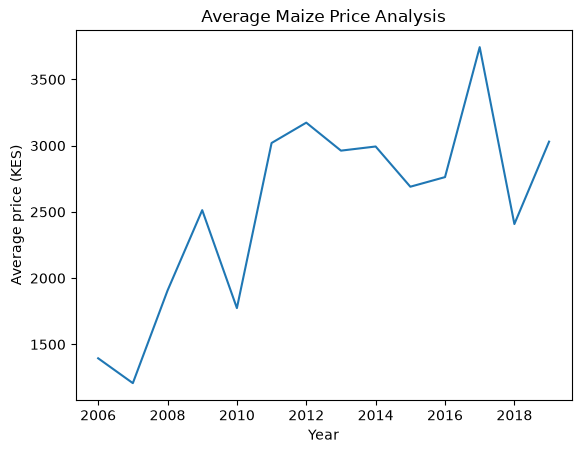

In [30]:
'''
Plot the yearly average as a line chart with the price in KES on the y-axis.

x- axis = year
y - axis = avg_price_kes
'''
x_values = yearly_avg["year"]
y_values = yearly_avg["avg_price_kes"]

plt.plot(x_values, y_values)
plt.xlabel("Year")
plt.ylabel("Average price (KES)")
plt.title("Average Maize Price Analysis")
plt.show()

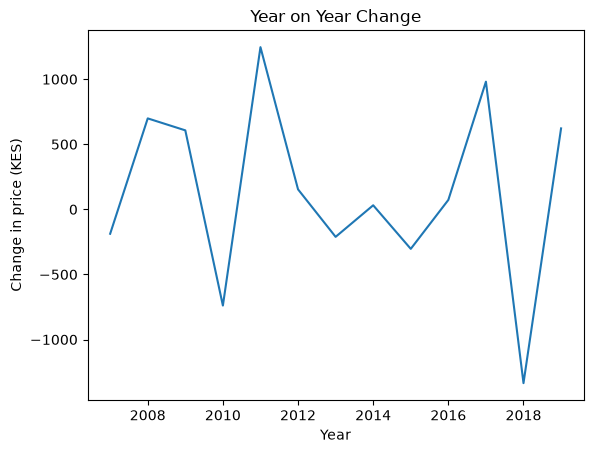

In [31]:
x_values = yearly_avg["year"]
y_values = yearly_avg["yoy_change_kes"]

plt.plot(x_values, y_values)
plt.xlabel("Year")
plt.ylabel("Change in price (KES)")
plt.title("Year on Year Change")
plt.show()

In [32]:
'''Sell at harvest or hold?
Average wholesale maize prices by month to find the seasonal pattern. Then compare each market's January and June price, year by year, to see how often storing maize for five months paid off.

- In which month is wholesale maize cheapest on average, and in which is it dearest?
- In what share of market-years was the June price higher than the January price, and what was the median gain?
- What costs and risks of storing maize does this calculation leave out?
'''
monthly_avg = df_maize.groupby('month')['price_kes'].mean().round(2)
monthly_avg.head()
# monthly_avg.columns = ['month', 'avg_month_kes']
# monthly_avg.columns
monthly_avg = monthly_avg.rename("avg_month_kes").reset_index()
monthly_avg

,month,avg_month_kes
0,1,2329.52
1,2,2405.34
2,3,2449.26
3,4,2626.68
4,5,2823.53
5,6,2839.47
6,7,2833.00
7,8,2695.38
8,9,2539.27
9,10,2442.57


In [33]:
# cheapest average month
# cheapest average month
cheap_month = monthly_avg.loc[monthly_avg['avg_month_kes'].idxmin(), 'month']
print(cheap_month) # January

dearest_month = monthly_avg.loc[monthly_avg['avg_month_kes'].idxmax(), 'month']
print(dearest_month) # June

print(f'Cheapest month; {cheap_month} , dearestmonth : {dearest_month}')

1
6
Cheapest month; 1 , dearestmonth : 6


In [34]:
# Compare January and June prices for each market-year
# In what share of market-years was the June price higher than the January price, and what was the median gain?
# What costs and risks of storing maize does this calculation leave out?
# Then compare each market's January and June price, year by year, to see how often storing maize for five months paid off.

# 1. Isolate your January records and your June records separately
jan_data = df_maize[df_maize["month"] == 1][["market", "year", "price_kes"]]

june_data = df_maize[df_maize["month"] == 6][["market", "year", "price_kes"]]

# 2. Merge them side-by-side on the matching Market and Year
# (We use suffixes to clearly label which price belongs to which month)
merged_df = pd.merge(jan_data, june_data, on=["market", "year"], suffixes=("_jan", "_june"))
merged_df
# # 3. Simply subtract the columns directly!
merged_df["gain_kes"] = merged_df["price_kes_june"] - merged_df["price_kes_jan"]
merged_df["profitable"] = merged_df["gain_kes"] > 0

print(merged_df.head(20))

     market  year  price_kes_jan  price_kes_june  gain_kes  profitable
0   Eldoret  2006         1192.0         1549.00    357.00        True
1   Eldoret  2007          947.5         1204.71    257.21        True
2   Eldoret  2008         1200.0         1776.00    576.00        True
3   Eldoret  2009         1743.0         2776.00   1033.00        True
4   Eldoret  2010         2142.0         1556.00   -586.00       False
5   Eldoret  2011         1390.0         3800.00   2410.00        True
6   Eldoret  2012         2800.0         2960.00    160.00        True
7   Eldoret  2013         2642.0         2710.00     68.00        True
8   Eldoret  2014         2794.0         3100.00    306.00        True
9   Eldoret  2015         2000.0         2550.00    550.00        True
10  Eldoret  2016         2210.0         2600.00    390.00        True
11  Eldoret  2017         2780.0         4320.00   1540.00        True
12  Eldoret  2018         2485.0         2030.00   -455.00       False
13  El

In [35]:
# Calculate the share of market-years where June was higher than January and the median gain
total_combinations = len(merged_df)
total_combinations
profitable_combinations = merged_df["profitable"].sum()
profitable_combinations
share_profitable = (profitable_combinations / total_combinations) * 100
share_profitable
# 2. Calculate the median gain
median_gain = merged_df["gain_kes"].median()
median_gain
print(f"Total Market-Years Analyzed: {total_combinations}")
print(f"Share of profitable market-years: {share_profitable:.2f}%")
print(f"Median Gain: KES {median_gain:.2f} per bag")

Total Market-Years Analyzed: 60
Share of profitable market-years: 73.33%
Median Gain: KES 356.00 per bag


## What costs and risks of storing maize does this calculation leave out?
The January-to-June comparison uses market prices only. It leaves out:

- **Storage losses:** weevils, the larger grain borer, rodents, moisture and mould. Aflatoxin can make maize unsellable.
Weight loss as the grain dries out in store.
- **Storage costs:** bags (hermetic bags), chemicals, a store or silo, and transport to market.
- **The cost of waiting:** the farmer may need cash at harvest for school fees, debts or inputs, and may have to borrow at interest.
Theft.
- **Price risk:** government actions (NCPB buying prices, duty-free imports) and good harvests in the region can push June prices down. In 1 in 4 market-years June was cheaper than January.
- **Farm-gate vs market prices:** these are wholesale market prices, but farmers usually sell to traders for less

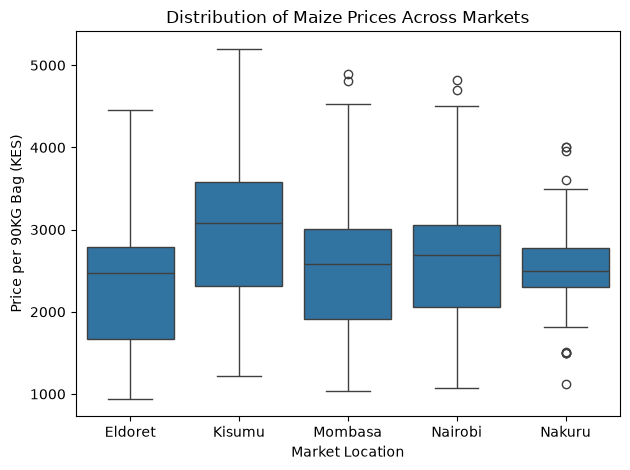

In [36]:
sns.boxplot(data=df_maize, x="market", y="price_kes")
# 2. Add the clean descriptive text layers
plt.title("Distribution of Maize Prices Across Markets")
plt.xlabel("Market Location")
plt.ylabel("Price per 90KG Bag (KES)")

# 3. Clean and display
plt.tight_layout()

In [37]:
df_maize.describe()

,date,price_kes,price_usd,year,month,price_per_kg
count,721,721.000000,721.000000,721.000000,721.000000,721.000000
mean,2013-04-27 13:44:51.262136,2568.807351,28.878904,2012.826630,6.486824,28.542304
min,2006-01-15 00:00:00,944.210000,11.120000,2006.000000,1.000000,10.491222
25%,2009-10-15 00:00:00,1989.000000,22.840000,2009.000000,3.000000,22.100000
50%,2013-07-15 00:00:00,2605.000000,28.900000,2013.000000,6.000000,28.944444
75%,2016-12-15 00:00:00,3100.000000,34.600000,2016.000000,9.000000,34.444444
max,2019-12-15 00:00:00,5200.000000,53.630000,2019.000000,12.000000,57.777778
std,NaN,849.836482,7.917711,4.072149,3.446843,9.442628


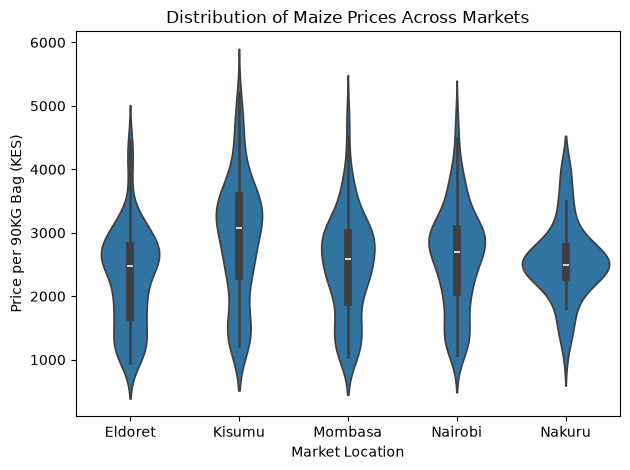

In [38]:
sns.violinplot(data=df_maize, x="market", y="price_kes")
# 2. Add the clean descriptive text layers
plt.title("Distribution of Maize Prices Across Markets")
plt.xlabel("Market Location")
plt.ylabel("Price per 90KG Bag (KES)")

# 3. Clean and display
plt.tight_layout()
plt.show()

In [39]:
# 1. Filter for Retail Maize between 2015 and 2019
df_retail_maize = df[
    (df["commodity"].str.lower() == "maize") & 
    (df["price_type"].str.lower() == "retail") & 
    (df["year"].between(2015, 2019))
].copy()

# 2. Get the Overall Average (2015-2019 combined) to find the absolute cheapest/most expensive
overall_avg = df_retail_maize.groupby("market")["price_kes"].mean().sort_values(ascending=False).reset_index()
overall_avg
print("--- OVERALL AVERAGE PRICES (2015-2019) ---")
print(overall_avg.round(2))

# 3. Get the Yearly Averages and Rank them within each year
yearly_market_avg = df_retail_maize.groupby(["year", "market"])["price_kes"].mean().reset_index()

# Create a ranking column where 1 is the most expensive market for that specific year
yearly_market_avg["rank"] = yearly_market_avg.groupby("year")["price_kes"].rank(ascending=False, method="min")

# 4. View the rankings side-by-side
rankings_pivot = yearly_market_avg.pivot(index="market", columns="year", values="rank")
print("\n--- MARKET RANKINGS BY YEAR (1 = Most Expensive) ---")
print(rankings_pivot)

--- OVERALL AVERAGE PRICES (2015-2019) ---
     market  price_kes
0    Lodwar      75.85
1   Mandera      67.53
2   Garissa      59.73
3   Kajiado      50.88
4      Hola      49.87
5  Marsabit      47.50
6   Marigat      46.53
7    Kilifi      43.84
8     Kitui      36.19

--- MARKET RANKINGS BY YEAR (1 = Most Expensive) ---
year      2015  2016  2017  2018  2019
market                                
Garissa    3.0   3.0   4.0   3.0   2.0
Hola       7.0   4.0   5.0   4.0   4.0
Kajiado    5.0   5.0   3.0   5.0   5.0
Kilifi     8.0   8.0   7.0   7.0   8.0
Kitui      9.0   9.0   9.0   9.0   9.0
Lodwar     1.0   1.0   1.0   1.0   3.0
Mandera    2.0   2.0   2.0   2.0   1.0
Marigat    6.0   7.0   6.0   8.0   6.0
Marsabit   4.0   6.0   8.0   6.0   7.0


In [40]:
# 1. Filter for Retail Maize between 2015 and 2019
df_retail_maize = df[
    (df["commodity"].str.lower() == "maize") & 
    (df["price_type"].str.lower() == "retail") & 
    (df["year"].between(2015, 2019))
].copy()

# 2. Get the Overall Average (2015-2019 combined) to find the absolute cheapest/most expensive
overall_avg = df_retail_maize.groupby("market")["price_kes"].mean().sort_values(ascending=False).reset_index()
overall_avg
print("--- OVERALL AVERAGE PRICES (2015-2019) ---")
print(overall_avg.round(2))

# 3. Get the Yearly Averages and Rank them within each year
yearly_market_avg = df_retail_maize.groupby(["year", "market"])["price_kes"].mean().reset_index()

# Create a ranking column where 1 is the most expensive market for that specific year
yearly_market_avg["rank"] = yearly_market_avg.groupby("year")["price_kes"].rank(ascending=False, method="min")

# 4. View the rankings side-by-side
rankings_pivot = yearly_market_avg.pivot(index="market", columns="year", values="rank")
print("\n--- MARKET RANKINGS BY YEAR (1 = Most Expensive) ---")
print(rankings_pivot)

--- OVERALL AVERAGE PRICES (2015-2019) ---
     market  price_kes
0    Lodwar      75.85
1   Mandera      67.53
2   Garissa      59.73
3   Kajiado      50.88
4      Hola      49.87
5  Marsabit      47.50
6   Marigat      46.53
7    Kilifi      43.84
8     Kitui      36.19

--- MARKET RANKINGS BY YEAR (1 = Most Expensive) ---
year      2015  2016  2017  2018  2019
market                                
Garissa    3.0   3.0   4.0   3.0   2.0
Hola       7.0   4.0   5.0   4.0   4.0
Kajiado    5.0   5.0   3.0   5.0   5.0
Kilifi     8.0   8.0   7.0   7.0   8.0
Kitui      9.0   9.0   9.0   9.0   9.0
Lodwar     1.0   1.0   1.0   1.0   3.0
Mandera    2.0   2.0   2.0   2.0   1.0
Marigat    6.0   7.0   6.0   8.0   6.0
Marsabit   4.0   6.0   8.0   6.0   7.0


## Answers: where households pay most (retail maize, 2015-2019)
- **Most expensive on average:** Lodwar, KES 75.85 per kg.
- **Cheapest on average:** Kitui, KES 36.19 per kg. Households in Lodwar paid about twice as much as households in Kitui.
- **Top three every year:** Lodwar and Mandera. Garissa came close but fell to 4th in 2017.
The note for Pamoja is in PAMOJA_NOTE.md.

Data: World Food Programme (WFP), via the Humanitarian Data Exchange (HDX).